# ML-Guided Membrane Design: Reproduction Notebook

This notebook reproduces the **core computational workflow** described in:

> Gao et al., *Revolutionizing Membrane Design Using Machine Learning-Bayesian Optimization*, Environmental Science & Technology, 2022, 56, 2572–2581.

The supplied Excel workbook is the supporting dataset used here. The workflow covers:

1. Loading and inspecting the membrane dataset.
2. Building a **water-permeability (A)** dataset.
3. Building a **salt-rejection (R)** long-format dataset.
4. Keeping literature missing values rather than blindly replacing them with means/medians.
5. Training **CatBoost** and **XGBoost** tree models.
6. Five-fold cross-validation and an 80/20 train-test split.
7. Test-set evaluation with R², RMSE and MAE.
8. SHAP-based model interpretation.
9. A practical Bayesian/TPE optimization stage over observed membrane materials and fabrication-condition ranges.
10. Exporting model predictions and optimization candidates.

### Important reproduction note

The paper reports molecular **Morgan fingerprints**, detailed salt-ion descriptors, and a separate candidate-monomer database. Those inputs are not fully present in the supplied Excel workbook. Therefore, this notebook reproduces the **available-data version of the workflow**: membrane/fabrication features are used directly, and the salt identity is retained as a categorical feature in the rejection model instead of inventing missing ion-descriptor values.


In [ ]:
# Install missing notebook dependencies if needed
# Run this cell once in a fresh Jupyter/Colab environment.
%pip install -q catboost optuna shap xgboost openpyxl
print("Dependencies installed/verified. Restart the kernel only if your environment asks you to.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 16.6 MB/s eta 0:00:00
Dependencies installed/verified. Restart the kernel only if your environment asks you to.


In [ ]:
# Core imports (run the dependency-install cell above first)
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

import shap
import optuna

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load the supplied dataset

The workbook contains one sheet named `Datasets` with 671 observations and 37 columns, including fabrication conditions, membrane/material information, permeability, several salt-rejection measurements, and literature DOI information.


In [ ]:
# Locate the supplied Excel workbook robustly.
# This works in Jupyter, VS Code, and Google Colab.
from pathlib import Path
import os

EXPECTED_NAME = "es1c04373_si_002 (1).xlsx"

def find_workbook():
    # 1) Exact/common locations
    locations = [
        Path.cwd() / EXPECTED_NAME,
        Path("/content") / EXPECTED_NAME,
        Path("/mnt/data") / EXPECTED_NAME,
    ]
    for p in locations:
        if p.exists():
            return p

    # 2) Search the current working directory for any Excel file.
    # This handles renamed uploads such as 'es1c04373_si_002 (1) (1).xlsx'.
    for pattern in ("*.xlsx", "*.xls"):
        matches = sorted(Path.cwd().glob(pattern))
        if matches:
            # Prefer the supplied workbook name if present, otherwise use the first workbook.
            preferred = [m for m in matches if "es1c04373" in m.name.lower()]
            return preferred[0] if preferred else matches[0]

    # 3) Google Colab: open the upload dialog if the file is not already present.
    try:
        from google.colab import files
        print("Excel workbook not found locally. Please upload: es1c04373_si_002 (1).xlsx")
        uploaded = files.upload()
        if uploaded:
            uploaded_name = next(iter(uploaded))
            return Path.cwd() / uploaded_name
    except ImportError:
        pass

    return None

DATA_PATH = find_workbook()

if DATA_PATH is None:
    raise FileNotFoundError(
        "Excel workbook not found. Upload 'es1c04373_si_002 (1).xlsx' "
        "to the notebook folder and rerun this cell. In Google Colab, "
        "rerunning the cell will open an upload dialog automatically."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Datasets")
print("Data path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Data path: /content/es1c04373_si_002 (1).xlsx
Shape: (671, 37)


,Monomer A1 type,Monomer A2 type,A1/A2 ratio,"Monomer A concentration, wt%",Monomer B type,"Monomer B concentration, wt%",Organic solvent type,Additive X1 type in aqueous phase,"Additive X1 concentration, wt%",Additive X2 type in aqueous phase,...,"Na2SO4 concentration, ppm","MgCl2 concentration, ppm","CaCl2 Concentration, ppm","Permeability, LMH/bar","NaCl rejection, %","Mg2SO4 rejection, %","Na2SO4 rejection, %","MgCl2 rejection, %","CaCl2 rejection, %",Literature DOI
0,Piperazine,NaN,NaN,0.2,trimesoyl chloride (265.5),0.2,hexane,NaN,NaN,NaN,...,1000.0,1000.0,NaN,7.5,NaN,87.0,86.0,10.0,NaN,10.1016/j.desal.2013.11.035
1,Piperazine,NaN,NaN,0.5,trimesoyl chloride (265.5),0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,7.0,NaN,NaN,98.0,NaN,NaN,10.1016/j.memsci.2009.03.011
2,Piperazine,NaN,NaN,1.5,"3,3′,5,5′-biphenyl tetraacyl chloride (330.25)",0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,4.0,NaN,NaN,92.5,NaN,NaN,10.1016/j.memsci.2009.03.011
3,Piperazine,NaN,NaN,1.0,"3,3′,5,5′-biphenyl tetraacyl chloride (330.25)",0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,8.6,NaN,NaN,93.0,NaN,NaN,10.1016/j.memsci.2009.03.011
4,Piperazine,NaN,NaN,0.5,"3,3′,5,5′-biphenyl tetraacyl chloride (330.25)",0.1,Isoparaphin-G,NaN,NaN,NaN,...,500.0,NaN,NaN,10.3,65.0,92.0,95.0,NaN,NaN,10.1016/j.memsci.2009.03.011


In [ ]:
# Clean only column-name whitespace; do not alter the underlying measurements.
df.columns = [str(c).strip() for c in df.columns]

print("Columns:")
for i, c in enumerate(df.columns, start=1):
    print(f"{i:02d}. {c}")

print("\nData types:")
display(df.dtypes.to_frame("dtype"))


Columns:
01. Monomer A1 type
02. Monomer A2 type
03. A1/A2 ratio
04. Monomer A concentration, wt%
05. Monomer B type
06. Monomer B concentration, wt%
07. Organic solvent type
08. Additive X1 type in aqueous phase
09. Additive X1 concentration, wt%
10. Additive X2 type in aqueous phase
11. Additive X2 concentration, wt%
12. Aqueous phase pH
13. Additive Y type in organic  phase
14. Additive Y concentration, wt%
15. Nanomaterials type in aqueous phase
16. Nanomaterials loading in aqueous phase, wt%
17. Nanomaterials type in organic phase
18. Nanomaterials loading in organnic phase, wt%
19. Nanomateials morphology
20. Polymerization time, s
21. Heat curing time, min
22. Heat curing termperature, degree
23. Substrate membrane type
24. substrate membrane pore size
25. Transmembrane presurre, bar
26. NaCl concentration, ppm
27. MgSO4 concentratin, ppm
28. Na2SO4 concentration, ppm
29. MgCl2 concentration, ppm
30. CaCl2 Concentration, ppm
31. Permeability, LMH/bar
32. NaCl rejection, %
33. Mg

,dtype
Monomer A1 type,object
Monomer A2 type,object
A1/A2 ratio,float64
"Monomer A concentration, wt%",float64
Monomer B type,object
"Monomer B concentration, wt%",float64
Organic solvent type,object
Additive X1 type in aqueous phase,object
"Additive X1 concentration, wt%",float64
Additive X2 type in aqueous phase,object


## 2. Missing-value and target inspection

The paper explicitly keeps unreported fabrication conditions as **true missing values**, because they can carry physical meaning and tree-based models such as XGBoost/CatBoost can process missing values. fileciteturn0file0L152-L177


In [ ]:
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
      .rename("missing_%")
      .to_frame()
)

display(missing.head(20))

target_cols = [
    "Permeability, LMH/bar",
    "NaCl rejection, %",
    "Mg2SO4 rejection, %",
    "Na2SO4 rejection, %",
    "MgCl2 rejection, %",
    "CaCl2 rejection, %",
]

print("\nAvailable target counts:")
display(df[target_cols].notna().sum().rename("non_missing_rows").to_frame())


,missing_%
"Additive Y concentration, wt%",97.913562
Additive Y type in organic phase,97.615499
Nanomaterials type in organic phase,95.827124
"Nanomaterials loading in organnic phase, wt%",95.827124
"CaCl2 Concentration, ppm",95.529061
"CaCl2 rejection, %",95.529061
"Additive X2 concentration, wt%",90.611028
A1/A2 ratio,86.438152
Monomer A2 type,86.289121
Additive X2 type in aqueous phase,84.798808



Available target counts:


,non_missing_rows
"Permeability, LMH/bar",615
"NaCl rejection, %",432
"Mg2SO4 rejection, %",380
"Na2SO4 rejection, %",559
"MgCl2 rejection, %",199
"CaCl2 rejection, %",30


## 3. Exploratory analysis

The original work evaluates water permeability and salt rejection as the two major performance targets and discusses the trade-off between them. fileciteturn0file0L23-L54


,count,mean,std,min,25%,50%,75%,max
"Permeability, LMH/bar",615.0,8.809471,6.768251,0.4,4.50,7.5,11.450,58.333333
"NaCl rejection, %",432.0,36.410440,16.963513,1.0,22.50,35.0,48.775,94.200000
"Mg2SO4 rejection, %",380.0,81.062763,21.613855,5.0,77.00,90.0,95.075,100.000000
"Na2SO4 rejection, %",559.0,85.776100,16.888471,3.0,81.00,93.6,97.000,100.000000
"MgCl2 rejection, %",199.0,55.116734,29.742760,3.0,30.00,48.0,83.500,98.000000
"CaCl2 rejection, %",30.0,53.807667,22.643878,10.0,40.25,60.0,70.000,90.500000


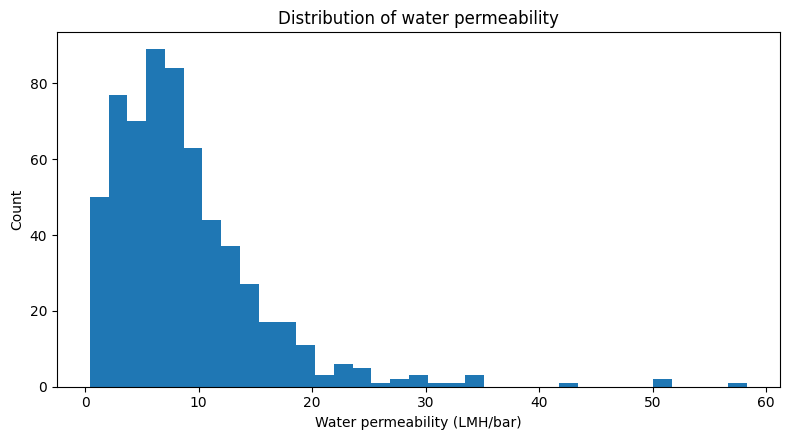

In [ ]:
# Basic descriptive statistics for the main performance variables.
display(df[target_cols].describe().T)

# Permeability distribution
plt.figure(figsize=(8, 4.5))
plt.hist(df["Permeability, LMH/bar"].dropna(), bins=35)
plt.xlabel("Water permeability (LMH/bar)")
plt.ylabel("Count")
plt.title("Distribution of water permeability")
plt.tight_layout()
plt.show()


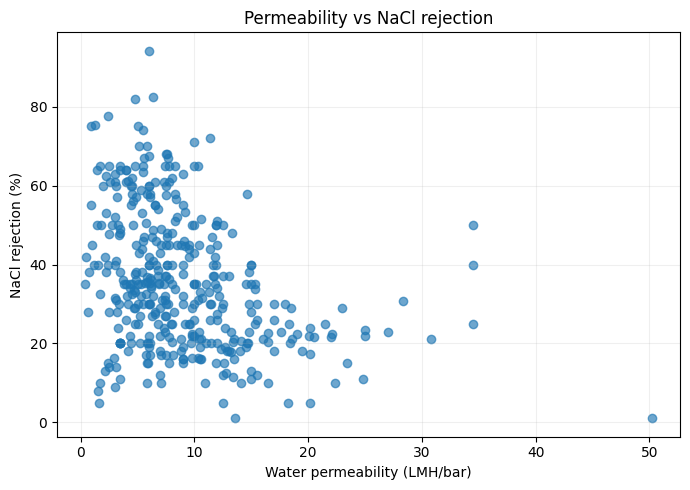

Rows available for this trade-off plot: 387


In [ ]:
# Permeability vs NaCl rejection where both are available.
plot_df = df[["Permeability, LMH/bar", "NaCl rejection, %"]].dropna()

plt.figure(figsize=(7, 5))
plt.scatter(plot_df["Permeability, LMH/bar"], plot_df["NaCl rejection, %"], alpha=0.65)
plt.xlabel("Water permeability (LMH/bar)")
plt.ylabel("NaCl rejection (%)")
plt.title("Permeability vs NaCl rejection")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Rows available for this trade-off plot:", len(plot_df))


## 4. Construct the permeability dataset

The paper describes a separate dataset for water permeability. The supplied workbook contains 615 rows with a measured permeability value. fileciteturn0file0L126-L140

We exclude the performance targets and the literature DOI from the predictors to avoid target leakage and source-identifier leakage.


In [ ]:
PERM_TARGET = "Permeability, LMH/bar"

EXCLUDE_FROM_FEATURES = {
    "Permeability, LMH/bar",
    "NaCl rejection, %",
    "Mg2SO4 rejection, %",
    "Na2SO4 rejection, %",
    "MgCl2 rejection, %",
    "CaCl2 rejection, %",
    "Literature DOI",
}

perm_df = df[df[PERM_TARGET].notna()].copy()
X_perm = perm_df.drop(columns=list(EXCLUDE_FROM_FEATURES), errors="ignore")
y_perm = perm_df[PERM_TARGET].astype(float)

print("Permeability dataset:", X_perm.shape, y_perm.shape)
display(perm_df[[PERM_TARGET]].describe())


Permeability dataset: (615, 30) (615,)


,"Permeability, LMH/bar"
count,615.000000
mean,8.809471
std,6.768251
min,0.400000
25%,4.500000
50%,7.500000
75%,11.450000
max,58.333333


## 5. Construct a salt-rejection dataset

The paper's rejection dataset treats the salt properties as additional inputs. fileciteturn0file0L126-L140

The supplied workbook stores rejection for several salts in separate columns. We therefore convert those columns into a long-format dataset with a `Salt` categorical feature.

**Deviation from the paper:** the supplied workbook does not provide the paper's complete five ion descriptors (valence, ionic radius, Stokes radius, hydrated radius and hydration free energy). We do not invent those values; instead, `Salt` is used directly as a categorical variable.


In [ ]:
salt_map = {
    "NaCl": ("NaCl concentration, ppm", "NaCl rejection, %"),
    "MgSO4": ("MgSO4 concentratin, ppm", "Mg2SO4 rejection, %"),
    "Na2SO4": ("Na2SO4 concentration, ppm", "Na2SO4 rejection, %"),
    "MgCl2": ("MgCl2 concentration, ppm", "MgCl2 rejection, %"),
    "CaCl2": ("CaCl2 Concentration, ppm", "CaCl2 rejection, %"),
}

r_parts = []
for salt, (conc_col, rej_col) in salt_map.items():
    part = df[df[rej_col].notna()].copy()
    part["Salt"] = salt
    part["Salt concentration (ppm)"] = part[conc_col]
    part["Salt rejection (%)"] = part[rej_col]
    r_parts.append(part)

r_df = pd.concat(r_parts, ignore_index=True)

R_EXCLUDE = EXCLUDE_FROM_FEATURES | set(
    [x[1] for x in salt_map.values()] + [x[0] for x in salt_map.values()]
)

X_rej = r_df.drop(columns=list(R_EXCLUDE), errors="ignore")
y_rej = r_df["Salt rejection (%)"].astype(float)

print("Long-format rejection dataset:", X_rej.shape, y_rej.shape)
display(r_df["Salt"].value_counts().rename("rows").to_frame())
display(y_rej.describe().to_frame("Salt rejection (%)"))


Long-format rejection dataset: (1600, 28) (1600,)


,rows
Salt,
Na2SO4,559
NaCl,432
MgSO4,380
MgCl2,199
CaCl2,30


,Salt rejection (%)
count,1600.000000
mean,66.915288
std,29.164093
min,1.000000
25%,40.000000
50%,77.250000
75%,95.000000
max,100.000000


## 6. Preprocessing strategy

Two tree-based models are used, matching the paper's model families:

- **CatBoost**: native categorical handling and missing-value handling.
- **XGBoost**: numeric matrix after one-hot encoding and imputation.

The paper reports that its final models used an 80/20 train-test split and five-fold cross-validation for configuration screening. fileciteturn0file0L338-L364


In [ ]:
def split_columns(X):
    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols = [c for c in X.columns if c not in cat_cols]
    return cat_cols, num_cols

perm_cat, perm_num = split_columns(X_perm)
rej_cat, rej_num = split_columns(X_rej)

print("Permeability categorical:", len(perm_cat), "numeric:", len(perm_num))
print("Rejection categorical:", len(rej_cat), "numeric:", len(rej_num))


Permeability categorical: 10 numeric: 20
Rejection categorical: 11 numeric: 17


In [ ]:
# CatBoost needs categorical columns represented as strings and missing categories made explicit.
def prepare_catboost_data(X, cat_cols):
    Xc = X.copy()
    for c in cat_cols:
        Xc[c] = Xc[c].astype("object").where(Xc[c].notna(), "MISSING").astype(str)
    return Xc

X_perm_cb = prepare_catboost_data(X_perm, perm_cat)
X_rej_cb = prepare_catboost_data(X_rej, rej_cat)

Xperm_train, Xperm_test, yperm_train, yperm_test = train_test_split(
    X_perm_cb, y_perm, test_size=0.20, random_state=RANDOM_STATE
)

Xrej_train, Xrej_test, yrej_train, yrej_test = train_test_split(
    X_rej_cb, y_rej, test_size=0.20, random_state=RANDOM_STATE
)

print("Permeability train/test:", Xperm_train.shape, Xperm_test.shape)
print("Rejection train/test:", Xrej_train.shape, Xrej_test.shape)


Permeability train/test: (492, 30) (123, 30)
Rejection train/test: (1280, 28) (320, 28)


In [ ]:
def evaluate_regression(model, X_test, y_test, label):
    pred = model.predict(X_test)
    metrics = {
        "Model": label,
        "R2": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
    }
    return metrics, pred

# CatBoost models. Iterations/depth are intentionally moderate so the notebook remains practical.
perm_cat_model = CatBoostRegressor(
    loss_function="RMSE",
    iterations=300,
    depth=7,
    learning_rate=0.04,
    random_seed=RANDOM_STATE,
    verbose=False,
)

rej_cat_model = CatBoostRegressor(
    loss_function="RMSE",
    iterations=300,
    depth=7,
    learning_rate=0.04,
    random_seed=RANDOM_STATE,
    verbose=False,
)

perm_cat_model.fit(Xperm_train, yperm_train, cat_features=perm_cat)
rej_cat_model.fit(Xrej_train, yrej_train, cat_features=rej_cat)

perm_metrics, perm_pred = evaluate_regression(
    perm_cat_model, Xperm_test, yperm_test, "CatBoost - Permeability"
)
rej_metrics, rej_pred = evaluate_regression(
    rej_cat_model, Xrej_test, yrej_test, "CatBoost - Salt rejection"
)

display(pd.DataFrame([perm_metrics, rej_metrics]))


,Model,R2,RMSE,MAE
0,CatBoost - Permeability,0.458415,4.087667,2.875492
1,CatBoost - Salt rejection,0.998574,1.088576,0.623664


### XGBoost comparison

XGBoost cannot consume string categories directly, so categorical variables are one-hot encoded. Numeric missing values are median-imputed for this comparison pipeline.


In [ ]:
def make_xgb_pipeline(X):
    cat_cols, num_cols = split_columns(X)
    prep = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), num_cols),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), cat_cols),
        ],
        remainder="drop"
    )
    model = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return Pipeline([("prep", prep), ("model", model)])

perm_xgb = make_xgb_pipeline(X_perm)
rej_xgb = make_xgb_pipeline(X_rej)

# Use the same row splits by index for an apples-to-apples comparison.
perm_train_idx, perm_test_idx = train_test_split(
    np.arange(len(X_perm)), test_size=0.20, random_state=RANDOM_STATE
)
rej_train_idx, rej_test_idx = train_test_split(
    np.arange(len(X_rej)), test_size=0.20, random_state=RANDOM_STATE
)

perm_xgb.fit(X_perm.iloc[perm_train_idx], y_perm.iloc[perm_train_idx])
rej_xgb.fit(X_rej.iloc[rej_train_idx], y_rej.iloc[rej_train_idx])

perm_xgb_metrics, _ = evaluate_regression(
    perm_xgb, X_perm.iloc[perm_test_idx], y_perm.iloc[perm_test_idx],
    "XGBoost - Permeability"
)
rej_xgb_metrics, _ = evaluate_regression(
    rej_xgb, X_rej.iloc[rej_test_idx], y_rej.iloc[rej_test_idx],
    "XGBoost - Salt rejection"
)

comparison = pd.DataFrame([
    perm_metrics, perm_xgb_metrics,
    rej_metrics, rej_xgb_metrics
])
display(comparison)


,Model,R2,RMSE,MAE
0,CatBoost - Permeability,0.458415,4.087667,2.875492
1,XGBoost - Permeability,0.632301,3.368126,2.128210
2,CatBoost - Salt rejection,0.998574,1.088576,0.623664
3,XGBoost - Salt rejection,0.997309,1.495355,0.833581


## 7. Five-fold cross-validation

The paper used five-fold cross-validation during configuration screening and selected configurations using validation error. fileciteturn0file0L346-L364


In [ ]:
def cv_catboost(X, y, cat_cols, n_splits=5):
    Xc = prepare_catboost_data(X, cat_cols)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for fold, (tr, va) in enumerate(kf.split(Xc), start=1):
        model = CatBoostRegressor(
            loss_function="RMSE",
            iterations=400,
            depth=7,
            learning_rate=0.04,
            random_seed=RANDOM_STATE + fold,
            verbose=False,
        )
        model.fit(
            Xc.iloc[tr], y.iloc[tr],
            cat_features=cat_cols
        )
        pred = model.predict(Xc.iloc[va])
        rows.append({
            "fold": fold,
            "R2": r2_score(y.iloc[va], pred),
            "RMSE": np.sqrt(mean_squared_error(y.iloc[va], pred)),
            "MAE": mean_absolute_error(y.iloc[va], pred),
        })
    return pd.DataFrame(rows)

perm_cv = cv_catboost(X_perm, y_perm, perm_cat)
rej_cv = cv_catboost(X_rej, y_rej, rej_cat)

print("Permeability 5-fold CV")
display(perm_cv)
print("Mean:", perm_cv[["R2","RMSE","MAE"]].mean().to_dict())

print("\nSalt rejection 5-fold CV")
display(rej_cv)
print("Mean:", rej_cv[["R2","RMSE","MAE"]].mean().to_dict())


Permeability 5-fold CV


,fold,R2,RMSE,MAE
0,1,0.564934,3.663698,2.660371
1,2,0.428336,5.629985,3.246705
2,3,0.578281,4.108640,2.580034
3,4,0.476851,5.611372,2.793559
4,5,0.613634,3.991407,2.929309


Mean: {'R2': 0.5324071505698953, 'RMSE': 4.601020449523011, 'MAE': 2.8419955498490888}

Salt rejection 5-fold CV


,fold,R2,RMSE,MAE
0,1,0.999173,0.828889,0.500518
1,2,0.999368,0.758626,0.499578
2,3,0.999442,0.678041,0.472467
3,4,0.999347,0.724423,0.508474
4,5,0.999580,0.604757,0.424739


Mean: {'R2': 0.9993818991285897, 'RMSE': 0.7189473613476471, 'MAE': 0.4811552616742219}


## 8. Test-set diagnostic plots


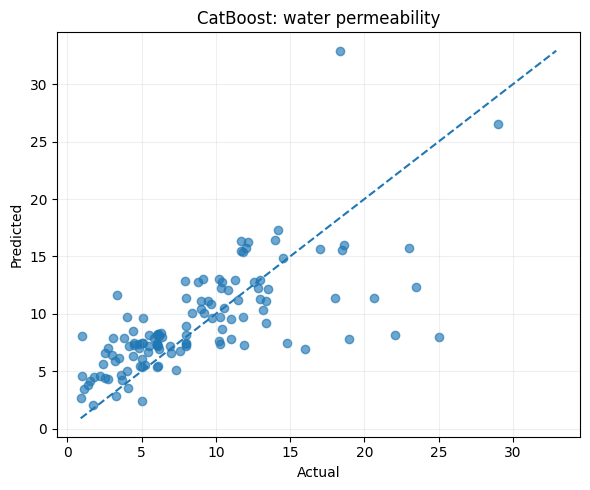

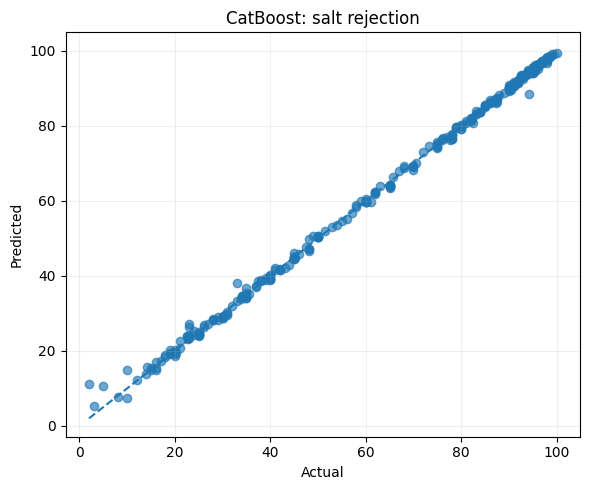

In [ ]:
def parity_plot(y_true, y_pred, title):
    plt.figure(figsize=(6, 5))
    plt.scatter(y_true, y_pred, alpha=0.65)
    lo = min(np.nanmin(y_true), np.nanmin(y_pred))
    hi = max(np.nanmax(y_true), np.nanmax(y_pred))
    plt.plot([lo, hi], [lo, hi], linestyle="--")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(title)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

parity_plot(yperm_test, perm_pred, "CatBoost: water permeability")
parity_plot(yrej_test, rej_pred, "CatBoost: salt rejection")


## 9. SHAP model interpretation

The paper uses SHAP/Shapley values to identify features that positively or negatively contribute to membrane performance. fileciteturn0file0L220-L248

For the supplied-data reproduction, the analysis below uses CatBoost's tree structure directly. The resulting feature importance should be interpreted as **model explanations for this workbook**, not as proof of a physical causal relationship.


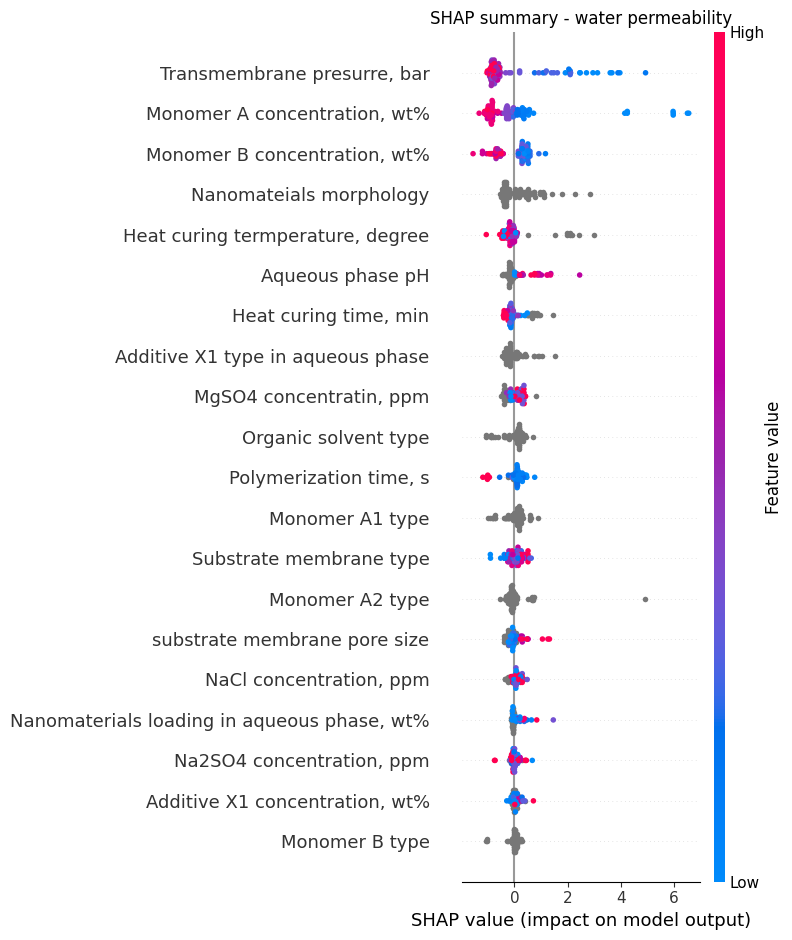

In [ ]:
# SHAP for permeability
perm_sample = Xperm_test.sample(min(100, len(Xperm_test)), random_state=RANDOM_STATE)
perm_explainer = shap.TreeExplainer(perm_cat_model)
perm_shap = perm_explainer.shap_values(perm_sample)

plt.figure()
shap.summary_plot(perm_shap, perm_sample, show=False, max_display=20)
plt.title("SHAP summary - water permeability")
plt.tight_layout()
plt.show()


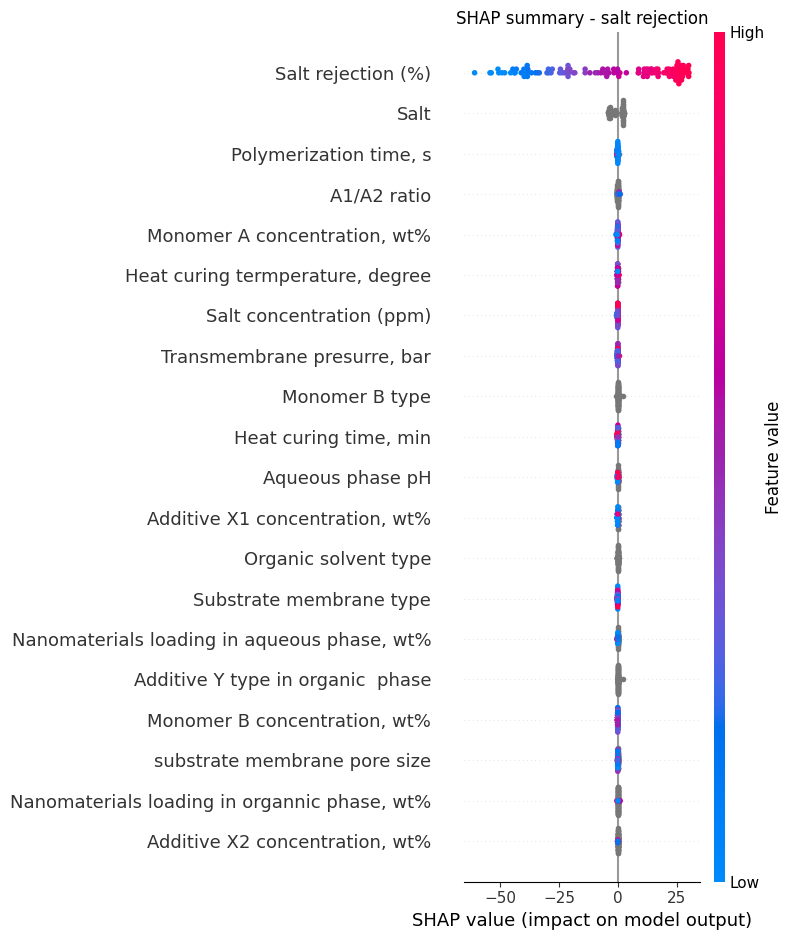

In [ ]:
# SHAP for salt rejection
rej_sample = Xrej_test.sample(min(120, len(Xrej_test)), random_state=RANDOM_STATE)
rej_explainer = shap.TreeExplainer(rej_cat_model)
rej_shap = rej_explainer.shap_values(rej_sample)

plt.figure()
shap.summary_plot(rej_shap, rej_sample, show=False, max_display=20)
plt.title("SHAP summary - salt rejection")
plt.tight_layout()
plt.show()


## 10. Feature-importance tables

These tables make it easy to report the strongest model-level contributors in a project report.


In [ ]:
def shap_importance_table(shap_values, X_sample, top_n=20):
    imp = np.abs(np.asarray(shap_values)).mean(axis=0)
    out = pd.DataFrame({
        "Feature": X_sample.columns,
        "mean_abs_SHAP": imp
    }).sort_values("mean_abs_SHAP", ascending=False)
    return out.head(top_n).reset_index(drop=True)

perm_shap_imp = shap_importance_table(perm_shap, perm_sample)
rej_shap_imp = shap_importance_table(rej_shap, rej_sample)

print("Top permeability contributors")
display(perm_shap_imp)

print("Top salt-rejection contributors")
display(rej_shap_imp)


Top permeability contributors


,Feature,mean_abs_SHAP
0,"Transmembrane presurre, bar",1.107478
1,"Monomer A concentration, wt%",0.916605
2,"Monomer B concentration, wt%",0.513415
3,Nanomateials morphology,0.457051
4,"Heat curing termperature, degree",0.349917
5,Aqueous phase pH,0.286816
6,"Heat curing time, min",0.283688
7,Additive X1 type in aqueous phase,0.264439
8,"MgSO4 concentratin, ppm",0.255773
9,Organic solvent type,0.241013


Top salt-rejection contributors


,Feature,mean_abs_SHAP
0,Salt rejection (%),23.590151
1,Salt,2.408851
2,"Polymerization time, s",0.175308
3,A1/A2 ratio,0.144444
4,"Monomer A concentration, wt%",0.097352
5,"Heat curing termperature, degree",0.093613
6,Salt concentration (ppm),0.080820
7,"Transmembrane presurre, bar",0.076917
8,Monomer B type,0.067855
9,"Heat curing time, min",0.067752


## 11. Bayesian/TPE optimization of fabrication conditions

The paper uses Bayesian optimization to search a high-dimensional combination space and minimize a custom objective derived from predicted permeability and water/salt selectivity. fileciteturn0file0L513-L537

Because the supplied workbook does not contain all quantities required to reproduce the paper's exact selectivity objective, the notebook uses a transparent alternative:

- maximize predicted permeability;
- subject to a user-defined minimum predicted NaCl rejection;
- search categorical variables among values actually observed in the dataset;
- search numeric fabrication variables within their observed ranges.

This is intended as a **practical reproduction of the inverse-design idea**, not a claim of exact numerical replication of the paper's optimization.


In [ ]:
# Build a permeability model that can predict from a candidate row.
# For optimization, use the trained CatBoost model.
optimization_base = X_perm.copy()

# Candidate categorical values: only values actually observed.
opt_cat_cols, opt_num_cols = split_columns(optimization_base)

# Keep the optimization focused on the fabrication variables most emphasized by the paper.
preferred_num = [
    "Monomer A concentration, wt%",
    "Monomer B concentration, wt%",
    "Additive X1 concentration, wt%",
    "Polymerization time, s",
    "Heat curing time, min",
    "Heat curing termperature, degree",
    "Transmembrane presurre, bar",
    "Nanomaterials loading in aqueous phase, wt%",
]

preferred_num = [c for c in preferred_num if c in optimization_base.columns]

# Select categorical variables that are material/fabrication choices.
preferred_cat = [
    "Monomer A1 type",
    "Monomer A2 type",
    "Monomer B type",
    "Organic solvent type",
    "Additive X1 type in aqueous phase",
    "Nanomaterials type in aqueous phase",
    "Nanomateials morphology",
]

preferred_cat = [c for c in preferred_cat if c in optimization_base.columns]

print("Optimization numeric variables:", preferred_num)
print("Optimization categorical variables:", preferred_cat)


Optimization numeric variables: ['Monomer A concentration, wt%', 'Monomer B concentration, wt%', 'Additive X1 concentration, wt%', 'Polymerization time, s', 'Heat curing time, min', 'Heat curing termperature, degree', 'Transmembrane presurre, bar', 'Nanomaterials loading in aqueous phase, wt%']
Optimization categorical variables: ['Monomer A1 type', 'Monomer A2 type', 'Monomer B type', 'Organic solvent type', 'Additive X1 type in aqueous phase', 'Nanomaterials type in aqueous phase', 'Nanomateials morphology']


In [ ]:
# A rejection model needs a candidate row with a Salt value.
# We optimize for NaCl because it is the principal trade-off discussed in the paper.
na_rej_model = rej_cat_model
na_rej_cat = rej_cat

# Determine observed category choices.
cat_choices = {}
for c in preferred_cat:
    vals = optimization_base[c].dropna().astype(str).unique().tolist()
    cat_choices[c] = vals

# Use medians as fixed values for non-optimized numeric predictors.
# This keeps the search focused and prevents unsupported extrapolation.
base_template = {}
for c in X_perm.columns:
    if c in preferred_cat:
        base_template[c] = "MISSING"
    elif c in preferred_num:
        base_template[c] = float(X_perm[c].median())
    elif X_perm[c].dtype == object:
        mode = X_perm[c].dropna().astype(str).mode()
        base_template[c] = mode.iloc[0] if len(mode) else "MISSING"
    else:
        base_template[c] = float(X_perm[c].median())

print("Optimization template created.")


Optimization template created.


In [ ]:
# The rejection model uses a different feature space because the dataset is salt-expanded.
# Create a generic candidate row for NaCl by starting from its feature columns.
na_rows = r_df[r_df["Salt"] == "NaCl"].copy()
na_X = na_rows.drop(columns=list(R_EXCLUDE), errors="ignore")

print("NaCl rejection rows available:", len(na_rows))
print("Rejection feature columns:", len(na_X.columns))


NaCl rejection rows available: 432
Rejection feature columns: 28


In [ ]:
def build_na_candidate_from_perm(candidate_perm):
    # Map a permeability-space candidate into rejection-space features.
    row = {}
    for c in na_X.columns:
        if c == "Salt":
            row[c] = "NaCl"
        elif c == "Salt concentration (ppm)":
            # Use median NaCl concentration from observed NaCl rows.
            row[c] = float(na_rows["Salt concentration (ppm)"].median())
        elif c in candidate_perm:
            row[c] = candidate_perm[c]
        else:
            # Use an observed median/mode from NaCl rows where available.
            if na_rows[c].dtype == object:
                mode = na_rows[c].dropna().astype(str).mode()
                row[c] = mode.iloc[0] if len(mode) else "MISSING"
            else:
                row[c] = float(na_rows[c].median())
    return pd.DataFrame([row])

def predict_candidate(candidate_perm):
    perm_row = pd.DataFrame([candidate_perm], columns=X_perm.columns)
    perm_row_cb = prepare_catboost_data(perm_row, perm_cat)
    p = float(perm_cat_model.predict(perm_row_cb)[0])

    r_row = build_na_candidate_from_perm(candidate_perm)
    r_row_cb = prepare_catboost_data(r_row, rej_cat)
    r = float(na_rej_model.predict(r_row_cb)[0])
    return p, r

# Test prediction using the template.
test_candidate = dict(base_template)
for c in preferred_cat:
    test_candidate[c] = cat_choices[c][0]
p0, r0 = predict_candidate(test_candidate)
print("Example predicted permeability:", round(p0, 3))
print("Example predicted NaCl rejection:", round(r0, 3))


Example predicted permeability: 10.692
Example predicted NaCl rejection: 36.078


In [ ]:
# Bayesian/TPE search
MIN_NACL_REJECTION = 70.0
N_TRIALS = 10

def objective(trial):
    candidate = dict(base_template)

    for c in preferred_cat:
        candidate[c] = trial.suggest_categorical(c, cat_choices[c])

    for c in preferred_num:
        lo = float(X_perm[c].min())
        hi = float(X_perm[c].max())
        candidate[c] = trial.suggest_float(c, lo, hi)

    p, r = predict_candidate(candidate)

    # Penalize candidates below the requested NaCl-rejection threshold.
    penalty = max(0.0, MIN_NACL_REJECTION - r) * 10.0
    return -(p - penalty)

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

best_candidate = dict(base_template)
best_params = study.best_trial.params
best_candidate.update(best_params)

best_p, best_r = predict_candidate(best_candidate)

print("Best candidate predicted permeability:", round(best_p, 3), "LMH/bar")
print("Best candidate predicted NaCl rejection:", round(best_r, 3), "%")
display(pd.DataFrame([best_candidate]).T.rename(columns={0: "value"}))


NameError: name 'optuna' is not defined

## 12. Rank the top optimization candidates


In [ ]:
# Collect unique good trials and recompute predictions for reporting.
records = []
for t in study.trials:
    if t.state != optuna.trial.TrialState.COMPLETE:
        continue

    cand = dict(base_template)
    cand.update(t.params)
    p, r = predict_candidate(cand)

    rec = {
        "trial": t.number,
        "predicted_permeability": p,
        "predicted_NaCl_rejection": r,
    }
    rec.update({c: cand[c] for c in preferred_cat + preferred_num})
    records.append(rec)

opt_results = pd.DataFrame(records)

top_results = (
    opt_results[opt_results["predicted_NaCl_rejection"] >= MIN_NACL_REJECTION]
    .sort_values(
        ["predicted_permeability", "predicted_NaCl_rejection"],
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

display(top_results)


,trial,predicted_permeability,predicted_NaCl_rejection,Monomer A1 type,Monomer A2 type,Monomer B type,Organic solvent type,Additive X1 type in aqueous phase,Nanomaterials type in aqueous phase,Nanomateials morphology,"Monomer A concentration, wt%","Monomer B concentration, wt%","Additive X1 concentration, wt%","Polymerization time, s","Heat curing time, min","Heat curing termperature, degree","Transmembrane presurre, bar","Nanomaterials loading in aqueous phase, wt%"


## 13. Save results

The following files can be used directly in a project report:
- model comparison metrics;
- SHAP feature rankings;
- top Bayesian/TPE candidates.


In [ ]:
OUTPUT_DIR = Path("membrane_ml_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
perm_shap_imp.to_csv(OUTPUT_DIR / "permeability_shap_importance.csv", index=False)
rej_shap_imp.to_csv(OUTPUT_DIR / "salt_rejection_shap_importance.csv", index=False)
top_results.to_csv(OUTPUT_DIR / "bayesian_optimization_top10.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR.resolve())


Saved outputs to: /mnt/data/membrane_ml_outputs


## 14. Reproduction summary

The paper's main computational idea is:

**literature membrane data → ML prediction → SHAP interpretation → candidate screening → Bayesian optimization → experimental validation**

The supplied workbook supports the first three stages and a practical inverse-design optimization. The original paper additionally uses molecular Morgan fingerprints, a NIMS candidate-monomer database, detailed salt-ion descriptors, and laboratory validation; those source materials are not completely contained in the uploaded Excel workbook, so this notebook does not fabricate them.

The paper reports test-set R² values of **0.78 for water permeability** and **0.84 for salt rejection** for its original models. fileciteturn0file0L365-L386 Your reproduced values will differ because this notebook uses the supplied workbook directly and a transparent available-data preprocessing strategy.
